<a href="https://colab.research.google.com/github/OmRohamare/stats_for_data/blob/main/descriptive_statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [2]:
import pandas as pd                    # load data, mean(), median(), mode()
import numpy as np                     # mean, median, weighted average
from scipy import stats                # trim_mean, gmean, hmean, mode
import matplotlib.pyplot as plt        # visualization
import seaborn as sns


In [3]:
file_path = "/content/drive/MyDrive/statsdata/house_sales.csv"
df = pd.read_csv(file_path, sep="\t")
df.head()

,DocumentDate,SalePrice,PropertyID,PropertyType,ym,zhvi_px,zhvi_idx,AdjSalePrice,NbrLivingUnits,SqFtLot,...,Bathrooms,Bedrooms,BldgGrade,YrBuilt,YrRenovated,TrafficNoise,LandVal,ImpsVal,ZipCode,NewConstruction
1,2014-09-16,280000,1000102,Multiplex,2014-09-01,405100,0.930836,300805.0,2,9373,...,3.00,6,7,1991,0,0,70000,229000,98002,False
2,2006-06-16,1000000,1200013,Single Family,2006-06-01,404400,0.929228,1076162.0,1,20156,...,3.75,4,10,2005,0,0,203000,590000,98166,True
3,2007-01-29,745000,1200019,Single Family,2007-01-01,425600,0.977941,761805.0,1,26036,...,1.75,4,8,1947,0,0,183000,275000,98166,False
4,2008-02-25,425000,2800016,Single Family,2008-02-01,418400,0.961397,442065.0,1,8618,...,3.75,5,7,1966,0,0,104000,229000,98168,False
5,2013-03-29,240000,2800024,Single Family,2013-03-01,351600,0.807904,297065.0,1,8620,...,1.75,4,7,1948,0,0,104000,205000,98168,False


In [4]:
unique_values = df["NbrLivingUnits"].unique()
unique_values

array([2, 1, 3, 4, 5])

In [5]:
unique_values1 = df["PropertyType"].unique()
unique_values1

array(['Multiplex', 'Single Family', 'Townhouse'], dtype=object)

In [6]:
unique_values_2 = df["Bedrooms"].unique()
unique_values_2.sort()  # Modifies unique_values_2 in-place
unique_values_2

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 11, 13, 33])

In [7]:
grade=df["BldgGrade"].unique()
grade

array([ 7, 10,  8,  6,  9,  5, 11, 12, 13,  4,  3])

In [8]:
# Finds rows where Bedrooms is exactly 3
df[df["Bedrooms"] == 0].sort_values(by=["SqFtLot"])


,DocumentDate,SalePrice,PropertyID,PropertyType,ym,zhvi_px,zhvi_idx,AdjSalePrice,NbrLivingUnits,SqFtLot,...,Bathrooms,Bedrooms,BldgGrade,YrBuilt,YrRenovated,TrafficNoise,LandVal,ImpsVal,ZipCode,NewConstruction
16940,2006-06-01,570000,6003500735,Townhouse,2006-06-01,404400,0.929228,613412.0,1,732,...,0.00,0,8,2006,0,0,114000,405000,98122,True
13459,2007-02-02,369950,3918400017,Townhouse,2007-02-01,427800,0.982996,376349.0,1,979,...,0.00,0,8,2006,0,0,93000,218000,98133,True
4177,2007-02-01,329000,1453602309,Townhouse,2007-02-01,427800,0.982996,334691.0,1,1650,...,1.50,0,7,1999,0,0,94000,196000,98125,False
16346,2006-01-13,224950,5466310010,Townhouse,2006-01-01,383200,0.880515,255476.0,1,2636,...,2.50,0,7,1983,0,0,70000,123000,98042,False
20492,2006-01-13,335105,7525211510,Townhouse,2006-01-01,383200,0.880515,380579.0,1,2752,...,0.00,0,8,1979,0,0,182000,177000,98052,False
26546,2014-10-23,65000,9543000205,Single Family,2014-10-01,407400,0.936121,69435.0,1,4269,...,0.00,0,7,1913,0,0,59000,66000,98001,False
1371,2010-05-18,140000,522059357,Single Family,2010-05-01,347800,0.799173,175181.0,1,5313,...,1.00,0,7,1943,1970,0,85000,82000,98031,False
17501,2006-07-26,438105,6181430780,Single Family,2006-07-01,407700,0.936811,467656.0,1,5523,...,0.00,0,7,2006,0,0,80000,240000,98001,True
11227,2011-03-03,257500,3374500520,Single Family,2011-03-01,321600,0.738971,348458.0,1,8049,...,0.00,0,8,1990,0,0,110000,204000,98031,False
11148,2008-01-02,256000,3356404960,Single Family,2008-01-01,421900,0.969439,264070.0,1,8787,...,1.75,0,7,1999,0,2,48000,149000,98001,False


In [9]:
# Finds rows where Bedrooms is exactly 3
df[df["Bedrooms"] == 33]


,DocumentDate,SalePrice,PropertyID,PropertyType,ym,zhvi_px,zhvi_idx,AdjSalePrice,NbrLivingUnits,SqFtLot,...,Bathrooms,Bedrooms,BldgGrade,YrBuilt,YrRenovated,TrafficNoise,LandVal,ImpsVal,ZipCode,NewConstruction
7278,2007-05-02,581000,2402100895,Single Family,2007-05-01,432100,0.992877,585168.0,1,6000,...,1.75,33,7,1947,0,0,414000,209000,98103,False


In [10]:
# 1. Filter out rows where 'Bedrooms' equals 0 or 33
#    - df["Bedrooms"].isin([0, 33]) creates a boolean mask of unwanted rows.
#    - The tilde (~) inverts the mask, keeping only valid rows.
df_cleaned = df[~df["Bedrooms"].isin([0, 33])]

# 2. Save the cleaned dataset back to the new CSV/TSV file
#    - sep="\t": Preserves tab-separated format.
#    - index=False: CRITICAL! Prevents pandas from writing row numbers (0, 1, 2...) into the file.
#      Why? Without this, pandas adds a new "Unnamed: 0" column each time the script is run.
#      With index=False, pandas will generate a fresh, gap-free index (0, 1, 2...) next time
#      it is loaded with pd.read_csv(), completely skipping the deleted rows.
df_cleaned.to_csv("/content/drive/MyDrive/statsdata/house_sales_cleaned.csv", sep="\t", index=False)

# 3. Feedback log (Safe to re-run: if re-run, dropped count will simply be 0)
print(f"Dropped {len(df) - len(df_cleaned)} rows. File updated successfully.")

Dropped 13 rows. File updated successfully.


In [11]:
# Finds rows where AT LEAST ONE of these three columns (LandVal, ImpsVal, or Bathrooms) equals 0
# - (df[...] == target_value): Checks each value and returns True if it equals 0, else False.
# - .any(axis=1): Checks across columns row-by-row (OR condition). Evaluates to True if ANY column is 0.
target_value = 0
matched_rows = df[(df[['LandVal', 'ImpsVal', 'Bathrooms',]] == target_value).any(axis=1)]
matched_rows

,DocumentDate,SalePrice,PropertyID,PropertyType,ym,zhvi_px,zhvi_idx,AdjSalePrice,NbrLivingUnits,SqFtLot,...,Bathrooms,Bedrooms,BldgGrade,YrBuilt,YrRenovated,TrafficNoise,LandVal,ImpsVal,ZipCode,NewConstruction
301,2007-09-14,799000,120059082,Single Family,2007-09-01,433500,0.996094,802133.0,1,435191,...,3.00,4,9,1965,0,0,0,0,98092,False
7341,2007-02-01,356000,2422059111,Single Family,2007-02-01,427800,0.982996,362158.0,1,60960,...,1.50,3,7,1967,0,0,0,0,98042,False
10029,2007-12-26,640000,3134100196,Single Family,2007-12-01,425200,0.977022,655052.0,1,17500,...,1.00,2,7,1955,0,1,0,0,98052,False
11227,2011-03-03,257500,3374500520,Single Family,2011-03-01,321600,0.738971,348458.0,1,8049,...,0.00,0,8,1990,0,0,110000,204000,98031,False
11361,2008-01-10,321000,3423059093,Single Family,2008-01-01,421900,0.969439,331119.0,1,31250,...,1.00,3,6,1960,0,2,0,0,98058,False
13263,2006-03-29,380000,3888100106,Single Family,2006-03-01,392100,0.900965,421770.0,1,7467,...,1.00,2,6,1940,0,0,0,0,98033,False
13303,2006-09-20,665000,3902100175,Single Family,2006-09-01,414800,0.953125,697705.0,1,5250,...,3.00,5,8,1931,0,2,0,0,98116,False
13459,2007-02-02,369950,3918400017,Townhouse,2007-02-01,427800,0.982996,376349.0,1,979,...,0.00,0,8,2006,0,0,93000,218000,98133,True
15568,2011-03-23,70000,5108400041,Single Family,2011-03-01,321600,0.738971,94726.0,1,7319,...,1.00,2,6,1962,0,3,0,0,98038,False
16940,2006-06-01,570000,6003500735,Townhouse,2006-06-01,404400,0.929228,613412.0,1,732,...,0.00,0,8,2006,0,0,114000,405000,98122,True


In [12]:
# Target value to search for
target_value = 0
cols_to_check = ["LandVal", "ImpsVal", "Bathrooms"]

# 2. Identify rows to DROP where AT LEAST ONE of these columns equals 0
#    - (df[cols_to_check] == target_value).any(axis=1) flags rows where ANY of the 3 columns is 0
#    - ~ (tilde) inverts the selection to KEEP rows where NONE of these columns are 0
drop_mask = (df[cols_to_check] == target_value).any(axis=1)
df_cleaned = df[~drop_mask]

#save cleaned file to drive
#    - sep="\t": Preserves tab-separated format
#    - index=False: Excludes the index numbers so no extra "Unnamed: 0" column is created
df_cleaned.to_csv("/content/drive/MyDrive/statsdata/house_sales_cleaned.csv", sep="\t", index=False)

# 4. Status log (safe to re-run: if re-run, dropped count will be 0)
print(f"Dropped {drop_mask.sum()} rows containing 0 in {cols_to_check}.")
print(f"Cleaned dataset saved back to: {"/content/drive/MyDrive/statsdata/house_sales_cleaned.csv"}")

Dropped 20 rows containing 0 in ['LandVal', 'ImpsVal', 'Bathrooms'].
Cleaned dataset saved back to: /content/drive/MyDrive/statsdata/house_sales_cleaned.csv


In [13]:
cleaned = pd.read_csv('/content/drive/MyDrive/statsdata/house_sales_cleaned.csv', sep='\t')
cleaned

,DocumentDate,SalePrice,PropertyID,PropertyType,ym,zhvi_px,zhvi_idx,AdjSalePrice,NbrLivingUnits,SqFtLot,...,Bathrooms,Bedrooms,BldgGrade,YrBuilt,YrRenovated,TrafficNoise,LandVal,ImpsVal,ZipCode,NewConstruction
0,2014-09-16,280000,1000102,Multiplex,2014-09-01,405100,0.930836,300805.0,2,9373,...,3.00,6,7,1991,0,0,70000,229000,98002,False
1,2006-06-16,1000000,1200013,Single Family,2006-06-01,404400,0.929228,1076162.0,1,20156,...,3.75,4,10,2005,0,0,203000,590000,98166,True
2,2007-01-29,745000,1200019,Single Family,2007-01-01,425600,0.977941,761805.0,1,26036,...,1.75,4,8,1947,0,0,183000,275000,98166,False
3,2008-02-25,425000,2800016,Single Family,2008-02-01,418400,0.961397,442065.0,1,8618,...,3.75,5,7,1966,0,0,104000,229000,98168,False
4,2013-03-29,240000,2800024,Single Family,2013-03-01,351600,0.807904,297065.0,1,8620,...,1.75,4,7,1948,0,0,104000,205000,98168,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22662,2011-04-08,325000,9842300710,Single Family,2011-04-01,318700,0.732307,443803.0,1,5468,...,1.75,3,7,1951,0,0,201000,172000,98126,False
22663,2007-09-28,1580000,9845500010,Single Family,2007-09-01,433500,0.996094,1586196.0,1,23914,...,4.50,4,11,2000,0,1,703000,951000,98040,False
22664,2012-07-09,165000,9899200010,Single Family,2012-07-01,325300,0.747472,220744.0,1,11170,...,1.00,4,6,1971,0,0,92000,130000,98055,False
22665,2006-05-26,315000,9900000355,Single Family,2006-05-01,400600,0.920496,342207.0,1,6223,...,2.00,3,7,1939,0,0,103000,212000,98166,False


1. Descriptive statistics

>**Central tendency**




In [14]:
#Mean of AdjSalePrice
avg_adjsale=cleaned["AdjSalePrice"].mean().round(2)


#Median of AdjSaleprice
med_adjsale=cleaned["AdjSalePrice"].median()

"""Trimmed mean: a statistical measure of central tendency that calculates the average of a dataset
after discarding a specific percentage or number of the highest and lowest values"""

#Trimmed Mean
trim_mean=stats.trim_mean(cleaned["AdjSalePrice"], 0.01).round(2)


print("Mean of AdjSalePrice=" ,avg_adjsale)
print("Median of AdjSalePrice=" ,med_adjsale)
print("Trimmed Mean of AdjSalePrice=" ,trim_mean)

print("\n--- Data Distribution Analysis ---")
print("The dataset is RIGHT-SKEWED (positively skewed) because:")
print("1. Mean > Median ($565.3k > $471.3k):")
print("   The standard average is pulled significantly upward by a small number")
print("   of extremely high-priced property sales (outliers) at the top end of the market.")
print("\n2. Trimmed Mean drops the average ($545.2k):")
print("   Removing just the extreme edges of the data slashes the mean by roughly $20,000.")
print("   This proves that the highest sales are disproportionately inflating the standard average.")
print("\n3. Market Realities:")
print("   Housing prices have a hard floor (cannot go below $0) but no ceiling.")
print("   A few multi-million dollar luxury estate sales create a long right 'tail',")
print("   while the majority of typical homes cluster at the lower end.")
print("----------------------------------")



Mean of AdjSalePrice= 565365.27
Median of AdjSalePrice= 471336.0
Trimmed Mean of AdjSalePrice= 545273.7

--- Data Distribution Analysis ---
The dataset is RIGHT-SKEWED (positively skewed) because:
1. Mean > Median ($565.3k > $471.3k):
   The standard average is pulled significantly upward by a small number
   of extremely high-priced property sales (outliers) at the top end of the market.

2. Trimmed Mean drops the average ($545.2k):
   Removing just the extreme edges of the data slashes the mean by roughly $20,000.
   This proves that the highest sales are disproportionately inflating the standard average.

3. Market Realities:
   Housing prices have a hard floor (cannot go below $0) but no ceiling.
   A few multi-million dollar luxury estate sales create a long right 'tail',
   while the majority of typical homes cluster at the lower end.
----------------------------------


In [15]:
#Geomteric mean of AdjSaleprice
adj_gmean = stats.gmean(df["AdjSalePrice"]).round(2)

print("Geometric mean of AdjSalePrice=", adj_gmean)


Geometric mean of AdjSalePrice= 495287.18


**Measures of Dispersion**

In [16]:
count_val, mean_val, std_val, min_val, q25_val, q50_val, q75_val, max_val = cleaned["AdjSalePrice"].describe()
populationstd=cleaned['AdjSalePrice'].std(ddof=0) #population Standard Deviation
print("Count =",count_val)
print("Mean =",round(mean_val,2))
print("Std =",round(std_val,2))
print("Min =",min_val)
print("25% =",q25_val)
print("50% =",q50_val)
print("75% =",q75_val)
print("Max =", max_val)

print(populationstd)

Count = 22667.0
Mean = 565365.27
Std = 385484.82
Min = 3368.0
25% = 360610.5
50% = 471336.0
75% = 649451.5
Max = 11644855.0
385476.31681214034


In [17]:
#variance AdjSalePrice
variance_adj=(std_val**2)

#Mean Absolute Deviation
mean_ad = (df['AdjSalePrice'] - df['AdjSalePrice'].mean()).abs().mean()
print(mean_ad)

print ("Variance=",round(variance_adj,2))

227155.58629680818
Variance= 148598546544.88


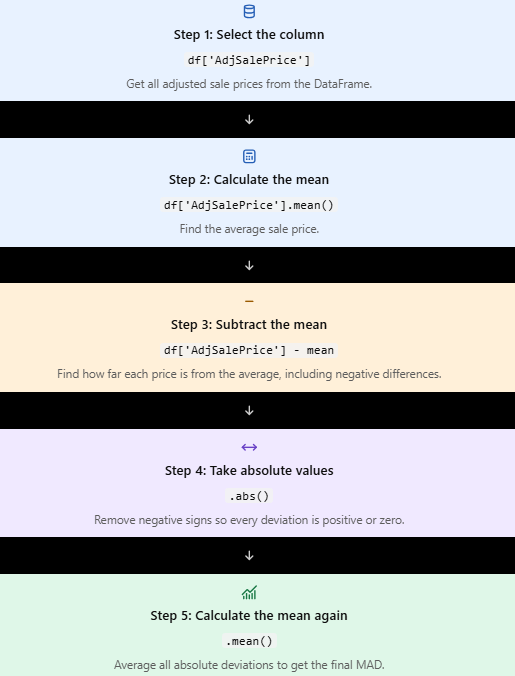

**To calculate the coefficient of variation (CV) in pandas**

| Operation | Pandas Syntax | Output Type |
|---|---|---|
| Single Column | df['col'].std() / df['col'].mean() | Float value |
| All Columns | df.std() / df.mean() | Pandas Series |
| Across Rows | df.std(axis=1) / df.mean(axis=1) | Pandas Series |
| By Group | df.groupby('grp')['col'].std() / df.groupby('grp')['col'].mean() | Pandas Series |


In [18]:
#Coefficient of variation
coeffofvar=std_val/mean_val
print(coeffofvar)

#Another method
coeffofvar_1= cleaned['AdjSalePrice'].std() / cleaned['AdjSalePrice'].mean()
print(coeffofvar_1)

0.6818332131566296
0.6818332131566296


**print(df.sem(axis=1))  # Row-wise Standard Error**

Key Parameters

• axis: Set to 0 or 'index' to calculate column-wise (default). Set to 1 or 'columns' to calculate row-wise.

• skipna: Set to True (default) to ignore missing values. If set to False, any row/column with a NaN will output NaN.

• ddof: Delta Degrees of Freedom (default is 1). The divisor used in the calculation is N - ddof.


Summary of Parameter Options


|Parameter	|Default Value|	Description|
|-----------|-------------|------------|
|axis	|0	|Direction of calculation (0 for columns, 1 for rows)
|skipna	|True|	Ignores missing/null values when calculating
|ddof	|1|	Adjusts the degrees of freedom (divisor is N - ddof)
|numeric_only|	True	|Includes only float, int, and boolean data




| Data Struture | Syntax | Output Type |
|----------|----------|----------|
| Series  | series.sem()	 | Scalar (Float)  |
| Single Column  | df['col_name'].sem()  | Scalar (Float)  |
|Multiple Columns | df[['col1', 'col2']].sem() | Series |
|Entire DataFrame | df.sem() | Series








In [19]:
#Standard Error of MEAN of AdjSalePrice
sem=cleaned['AdjSalePrice'].sem()
print("Standard Error of Mean of AdjSalePrice=",round(sem,2))

Standard Error of Mean of AdjSalePrice= 2560.41


***DECILE*** : A decile is a statistical measure that divides a sorted dataset into 10 equal parts, with each part representing 10% of the total data.

• **Quartiles:** Divide data into 4 quarters (25% each).

• **Deciles:** Divide data into 10 parts (10% each).

• **Percentiles:** Divide data into 100 parts (1% each).

In [20]:
#Decile of AdjSalePrice
# Divide the 'scores' column into 10 equal-sized bins (deciles).
# - labels=False: Returns raw numbers (0-9) instead of messy interval ranges like (12.3, 45.1].
# - + 1: Shifts the 0-9 python index to a human-friendly 1-10 ranking scale.
# 1. Create a NEW column for the decile ranks so you don't overwrite the raw prices
cleaned['AdjSalePrice_Decile'] = pd.qcut(cleaned['AdjSalePrice'], q=10, labels=False) + 1
print("Decile Ranks (Sample):")
print(cleaned['AdjSalePrice_Decile'])


Decile Ranks (Sample):
0         2
1        10
2         9
3         5
4         2
         ..
22662     5
22663    10
22664     1
22665     3
22666     6
Name: AdjSalePrice_Decile, Length: 22667, dtype: int64


• Row 0 has a decile of 2, meaning its price falls within the bottom 10% to 20% of all sales.

• Row 1 has a decile of 10, meaning it is among the top 10% most expensive homes in your entire dataset.

• Row 22664 has a decile of 1, placing it in the bottom 10% cheapest homes.


In [21]:
# Get cutoff values at 0.1, 0.2, ..., 1.0
# 2. Get cutoff values using the original df (or cleaned before it got overwritten)
# Note: Ensure 'df' or 'cleaned' holds the raw dollar amounts here
decile_cutoffs = cleaned['AdjSalePrice'].quantile(np.linspace(0.1, 1.0, 10))
print("\nActual Price Cutoffs for each Decile:")
print(decile_cutoffs)



Actual Price Cutoffs for each Decile:
0.1      289647.2
0.2      339211.4
0.3      381768.4
0.4      423655.8
0.5      471336.0
0.6      528253.6
0.7      601716.0
0.8      708112.0
0.9      896273.2
1.0    11644855.0
Name: AdjSalePrice, dtype: float64


• Decile 1 (Bottom 10%): Properties priced up to $289,603.

• Decile 5 (Median / 50%): The exact midpoint price of your dataset is $471,315. Half the homes cost less than this; half cost more.

• Decile 9 (Top 10% Cutoff): Any property priced above $896,259.20 enters the elite 10th decile tier.

• Decile 10 (Maximum): The most expensive property in dataset sold for $11,644,855.


In [22]:
# 3. Calculate percentiles on the original raw prices
percentile = cleaned["AdjSalePrice"].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
print("\nPercentiles of Raw Prices:")
print(percentile)


Percentiles of Raw Prices:
0.01     180148.06
0.05     254070.00
0.25     360610.50
0.50     471336.00
0.75     649451.50
0.95    1155076.10
0.99    2049744.90
Name: AdjSalePrice, dtype: float64


In [23]:
"""• Result > 0: Right-skewed (positive skew, long tail on the right).
• Result < 0: Left-skewed (negative skew, long tail on the left).
• Result ≈ 0: Symmetric distribution."""
# Calculate skewness
skew=cleaned['AdjSalePrice'].skew()
print("Skewness of AdjSalePrice=",round(skew,2))

"""• Result > 0: Leptokurtic (sharp peak, heavy tails).
• Result < 0: Platykurtic (flat peak, light tails).
• Result ≈ 0: Mesokurtic (normal distribution).
"""

#Calculate kurtosis
kurtosis=cleaned['AdjSalePrice'].kurt()
print("Kurtosis of AdjSalePrice=",round(kurtosis,2))





Skewness of AdjSalePrice= 5.85
Kurtosis of AdjSalePrice= 78.32


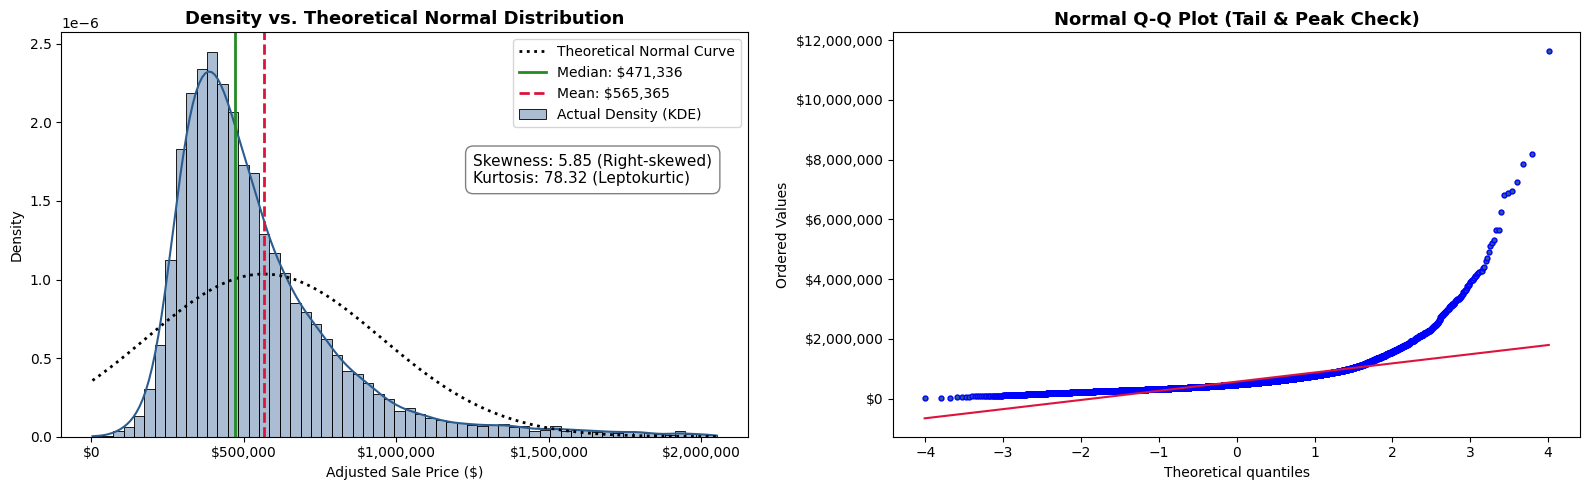

In [24]:

median_val = cleaned['AdjSalePrice'].median()

# 2. Set up a 2-panel figure
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# -------------------------------------------------------------
# Panel 1: Distribution vs. Fitted Normal Curve (Kurtosis & Skew)
# -------------------------------------------------------------
# Truncate x-axis visually to 99th percentile to see the peak clearly
# without 11M+ extreme outliers compressing the main distribution
x_limit = cleaned['AdjSalePrice'].quantile(0.99)
plot_data = cleaned['AdjSalePrice'][cleaned['AdjSalePrice'] <= x_limit]

# Plot actual data histogram and KDE
sns.histplot(plot_data, kde=True, stat="density", bins=60,
             color="#2b5c8f", alpha=0.4, ax=axes[0], label="Actual Density (KDE)")

# Plot theoretical Normal distribution curve with identical mean & std
x_range = np.linspace(plot_data.min(), x_limit, 500)
normal_curve = stats.norm.pdf(x_range, mean_val, std_val)
axes[0].plot(x_range, normal_curve, color="black", linestyle=":", linewidth=2, label="Theoretical Normal Curve")

# Vertical markers for Mean and Median (Skewness markers)
axes[0].axvline(median_val, color="forestgreen", linestyle="-", linewidth=2, label=f"Median: ${median_val:,.0f}")
axes[0].axvline(mean_val, color="crimson", linestyle="--", linewidth=2, label=f"Mean: ${mean_val:,.0f}")

# Annotation box for metrics
metrics_text = (
    f"Skewness: {skew:.2f} (Right-skewed)\n"
    f"Kurtosis: {kurtosis:.2f} (Leptokurtic)"
)
axes[0].text(0.60, 0.70, metrics_text, transform=axes[0].transAxes, fontsize=11,
             verticalalignment="top", bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray"))

axes[0].set_title("Density vs. Theoretical Normal Distribution", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Adjusted Sale Price ($)")
axes[0].set_ylabel("Density")
axes[0].xaxis.set_major_formatter("${x:,.0f}")
axes[0].legend(loc="upper right")

# -------------------------------------------------------------
# Panel 2: Normal Q-Q Plot (Quantile-Quantile Diagnostic)
# -------------------------------------------------------------
# Q-Q plot compares actual quantiles against theoretical normal quantiles
stats.probplot(cleaned['AdjSalePrice'], dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q Plot (Tail & Peak Check)", fontsize=13, fontweight="bold")
axes[1].get_lines()[0].set_markerfacecolor("#2b5c8f")
axes[1].get_lines()[0].set_markersize(3.5)
axes[1].get_lines()[1].set_color("crimson")
axes[1].yaxis.set_major_formatter("${x:,.0f}")

plt.tight_layout()
plt.show()

In [25]:
# DocumentDate is read as plain text. Convert it to a real date
# so we can pull out the year with .dt.year
cleaned["DocumentDate"] = pd.to_datetime(cleaned["DocumentDate"])


# ---------- 1. CREATE THE TWO DERIVED COLUMNS ----------
# Age of the house at the time it was sold = sale year - year it was built
cleaned["house_age"] = cleaned["DocumentDate"].dt.year - cleaned["YrBuilt"]

# Price per square foot of living space = how much each sq ft cost
cleaned["price_per_sqft"] = cleaned["SalePrice"] / cleaned["SqFtTotLiving"]


# ---------- 2. CHOOSE WHICH COLUMNS TO SUMMARIZE ----------
cols = ["SalePrice", "AdjSalePrice", "SqFtTotLiving", "SqFtLot",
        "SqFtFinBasement", "LandVal", "ImpsVal", "price_per_sqft", "house_age"]


# ---------- 3. FUNCTION THAT COMPUTES ALL STATISTICS FOR ONE COLUMN ----------
def describe_full(s):
    # s is one column (a pandas Series). Drop missing values so they don't break the maths.
    s = s.dropna()

    # Return a Series: each entry is one statistic, with its name as the label
    return pd.Series({

        # --- CENTRAL TENDENCY: "what is a typical value?" ---
        "mean": s.mean(),                          # average; pulled up by very large values
        "median": s.median(),                      # middle value; not affected by extremes
        "mode": s.mode().iloc[0],                  # most frequent value (.mode() can return
                                                   # several ties, so we take the first)
        "trimmed_mean": stats.trim_mean(s, 0.1),   # mean after cutting the lowest 10% and
                                                   # highest 10%, so outliers matter less
        "geo_mean": stats.gmean(s[s > 0]),         # geometric mean; only works on positive
                                                   # numbers, so zeros are filtered out

        # --- DISPERSION: "how spread out are the values?" ---
        "var": s.var(),                            # variance (average squared distance from mean)
        "std": s.std(),                            # standard deviation (same units as the data)
        "range": s.max() - s.min(),                # biggest minus smallest
        "iqr": stats.iqr(s),                       # interquartile range: p75 - p25 (middle 50%)
        "mad": stats.median_abs_deviation(s),      # median absolute deviation; a spread
                                                   # measure that ignores outliers
        "cv": s.std() / s.mean(),                  # coefficient of variation: spread relative
                                                   # to the mean, so you can compare variables
                                                   # with different units
        "sem": stats.sem(s),                       # standard error of the mean: how uncertain
                                                   # the mean is (shrinks as n grows)

        # --- POSITION: "where do values sit?" ---
        "min": s.min(),
        "p1": s.quantile(.01),                     # 1% of values are below this
        "p5": s.quantile(.05),
        "p25": s.quantile(.25),                    # first quartile
        "p75": s.quantile(.75),                    # third quartile
        "p95": s.quantile(.95),
        "p99": s.quantile(.99),                    # 99% of values are below this
        "max": s.max(),

        # --- SHAPE: "what does the distribution look like?" ---
        "skew": stats.skew(s),                     # > 0 = long tail to the right,
                                                   # < 0 = long tail to the left, 0 = symmetric
        "kurtosis": stats.kurtosis(s),             # > 0 = heavier tails than a normal curve
                                                   # (more extreme values), < 0 = lighter tails
    })


# ---------- 4. APPLY THE FUNCTION TO EVERY COLUMN ----------
# cleaned[cols] selects only our 9 columns.
# .apply(describe_full) runs the function on each column, giving one column of results per variable.
# .T transposes the table so variables become rows and statistics become columns.
summary = cleaned[cols].apply(describe_full).T

# Print the table, rounded to 2 decimals for readability
print(summary.round(2))

                      mean     median      mode  trimmed_mean   geo_mean  \
SalePrice        508026.46  424800.00  350000.0     453248.70  444442.92   
AdjSalePrice     565365.27  471336.00  477458.0     503516.57  495453.06   
SqFtTotLiving      2080.36    1910.00    1560.0       1984.29    1904.39   
SqFtLot           11724.52    7200.00    5000.0       7433.05    7136.57   
SqFtFinBasement     293.35       0.00       0.0        209.81     635.98   
LandVal          220478.62  182000.00   90000.0     189373.58  179002.06   
ImpsVal          300668.97  246000.00  183000.0     266516.65  245679.49   
price_per_sqft      249.48     233.74     250.0        239.72     233.38   
house_age            36.78      31.00       0.0         34.15      24.96   

                          var        std       range        iqr        mad  \
SalePrice        1.202026e+11  346702.45  10997000.0  260000.00  119800.00   
AdjSalePrice     1.485985e+11  385484.82  11641487.0  288841.00  131402.00   
SqFtT

In [26]:
features = [
    "PropertyType",
    "Bedrooms",
    "Bathrooms",
    "BldgGrade",
    "TrafficNoise",
    "NewConstruction",
    "NbrLivingUnits",
]

# Display count and percentage for each feature
for col in features:
    print(f"\n--- Frequency for {col} ---")
    summary = (
        pd.DataFrame(
            {"Count": df[col].value_counts(), "Percent (%)": df[col].value_counts(normalize=True) * 100}
        )
        .round(2)

    )  # adjust head() as needed
    print(summary)


--- Frequency for PropertyType ---
               Count  Percent (%)
PropertyType                     
Single Family  20720        91.33
Townhouse       1710         7.54
Multiplex        257         1.13

--- Frequency for Bedrooms ---
          Count  Percent (%)
Bedrooms                    
3         10178        44.86
4          7619        33.58
2          2936        12.94
5          1484         6.54
6           246         1.08
1           153         0.67
7            40         0.18
0            12         0.05
8            10         0.04
9             5         0.02
11            2         0.01
13            1         0.00
33            1         0.00

--- Frequency for Bathrooms ---
           Count  Percent (%)
Bathrooms                    
2.50        6182        27.25
1.00        3473        15.31
1.75        3094        13.64
2.00        2198         9.69
2.25        1971         8.69
1.50        1386         6.11
2.75        1327         5.85
3.50         869        

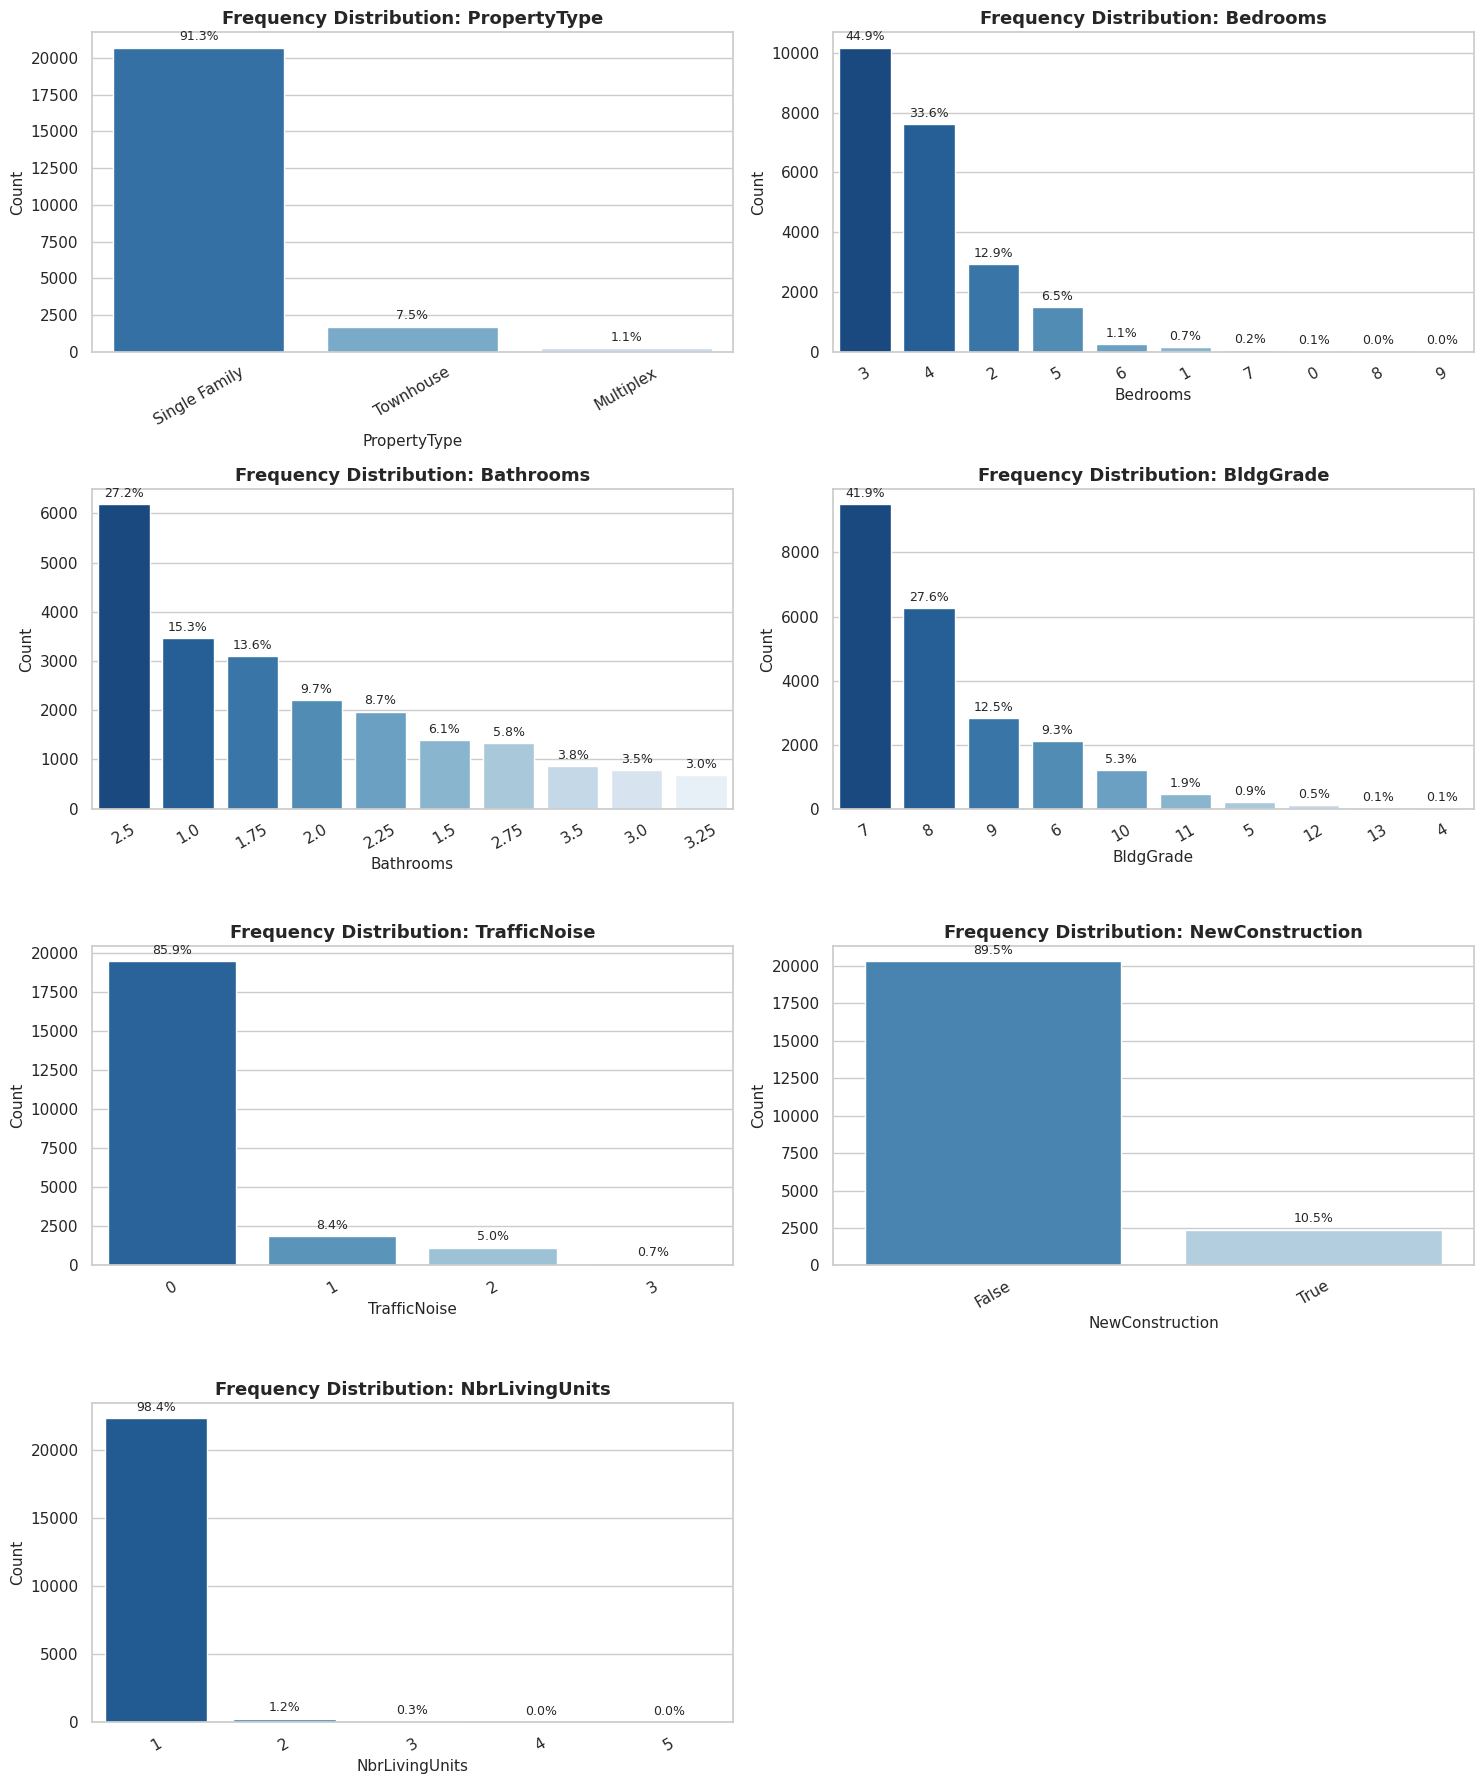

In [28]:
# Set overall aesthetic
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 18))
axes = axes.flatten()

total_rows = len(df)

for i, col in enumerate(features):
    ax = axes[i]

    # Get top 10 most frequent values
    top_counts = df[col].value_counts().head(10)
    x_vals = top_counts.index.astype(str)
    y_vals = top_counts.values

    # Pass hue=x_vals and legend=False to prevent deprecation warning
    sns.barplot(
        x=x_vals,
        y=y_vals,
        hue=x_vals,
        legend=False,
        palette="Blues_r",
        ax=ax,
    )

    ax.set_title(f"Frequency Distribution: {col}", fontsize=13, weight="bold")
    ax.set_xlabel(col, fontsize=11)
    ax.set_ylabel("Count", fontsize=11)
    ax.tick_params(axis="x", rotation=30)

    # Annotate percentage on top of each bar
    for p in ax.patches:
        height = p.get_height()
        if not np.isnan(height) and height > 0:
            percentage = (height / total_rows) * 100
            ax.annotate(
                f"{percentage:.1f}%",
                (p.get_x() + p.get_width() / 2.0, height),
                ha="center",
                va="bottom",
                fontsize=9,
                xytext=(0, 3),
                textcoords="offset points",
            )

# Hide the unused 8th subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

In [29]:
# ---------- 1. CREATE THE "RENOVATED" FLAG ----------
# YrRenovated = 0 means "never renovated", so any value above 0 means renovated.
# This gives a True/False column we can group by.
df["renovated"] = df["YrRenovated"] > 0

# ---------- 2. THE GROUPING COLUMNS ----------
group_cols = ["PropertyType", "BldgGrade", "ZipCode",
              "NewConstruction", "TrafficNoise", "renovated"]

# ---------- 3. FUNCTION: SUMMARIZE PRICE FOR ONE GROUPING ----------
def group_describe(df, group_col, value_col="SalePrice"):
    # groupby splits the rows into groups by the values in group_col.
    # [value_col] keeps only the price column inside each group.
    g = df.groupby(group_col)[value_col]

    out = g.agg(
        n="count",           # how many sales are in the group
        mean="mean",         # average price (pulled up by expensive sales)
        median="median",     # middle price (more reliable with skewed data)
        std="std",           # spread within the group
        min="min",
        max="max",
    )

    # Quartiles are not in the simple agg list, so add them separately.
    out["p25"] = g.quantile(0.25)
    out["p75"] = g.quantile(0.75)

    # Share of all sales that fall in this group, useful for spotting tiny groups
    out["pct_of_sales"] = (out["n"] / out["n"].sum() * 100).round(1)

    # Reorder the columns so the table reads left to right
    return out[["n", "pct_of_sales", "min", "p25", "median", "mean", "p75", "max", "std"]]

# ---------- 4. RUN IT FOR EACH GROUPING ----------
for col in group_cols:
    print(f"\n===== SalePrice by {col} =====")
    table = group_describe(df, col)

    if col == "ZipCode":
        # 80 zip codes is too many to read. Keep only zips with at least 100 sales
        # (tiny groups give unreliable statistics) and sort by median price.
        table = table[table["n"] >= 100].sort_values("median", ascending=False)

    print(table.round(0))

# ---------- 5. REPEAT ON LOG PRICE OR ADJUSTED PRICE (OPTIONAL) ----------
# AdjSalePrice removes the effect of market-wide price changes over time,
# so group differences are less mixed up with the 2008 crash and recovery.
print(group_describe(df, "BldgGrade", value_col="AdjSalePrice").round(0))


===== SalePrice by PropertyType =====
                   n  pct_of_sales     min       p25    median      mean  \
PropertyType                                                               
Multiplex        257           1.0  120000  359950.0  478210.0  499526.0   
Single Family  20720          91.0   10480  326000.0  429327.0  517038.0   
Townhouse       1710           8.0    3000  316777.0  379900.0  398757.0   

                    p75       max       std  
PropertyType                                 
Multiplex      600000.0   1675000  191583.0  
Single Family  599950.0  11000000  358495.0  
Townhouse      450000.0   2060000  135964.0  

===== SalePrice by BldgGrade =====
              n  pct_of_sales      min        p25     median       mean  \
BldgGrade                                                                 
3             1           0.0    59000    59000.0    59000.0    59000.0   
4            12           0.0    57000   157500.0   223975.0   215038.0   
5           19